# Ноутбуки для GitHub.
---
## Тема 5. Законы распределения дискретных случайных величин
---

**Задание:** Привести примеры дискретных случайных величин, распределенных по:
- биномиальному закону распределения;
- закону распределения Пуассона;
- геометрическому закону распределения;
- гипергеометрическому закону распределения.

Для каждой ДСВ составить закон распределения, найти математическое ожидание, дисперсию, среднее квадратическое отклонение и моду, отобразить многоугольник распределения.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy.stats import binom, poisson, geom, hypergeom

pd.options.display.float_format = '{:.6f}'.format
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})

def distribution_table(x, probabilities):
    return pd.DataFrame({'k': x, 'P(X = k)': probabilities})

def modes_from_pmf(x, probabilities):
    return x[np.isclose(probabilities, probabilities.max(), rtol=1e-10, atol=1e-14)].tolist()


def characteristics(rv, modes):
    return pd.DataFrame({
        'Характеристика': ['M(X)', 'D(X)', 'σ(X)', 'Мода'],
        'Значение': [f'{rv.mean():.6f}', f'{rv.var():.6f}', f'{rv.std():.6f}', str(modes)]
    })


def polygon(x, probabilities, title, xlabel, modes, color, tail=None):
    fig, ax = plt.subplots(figsize=(8.5, 4))
    ax.plot(x, probabilities, 'o-', color=color, linewidth=1.8, markersize=5,
            label='Многоугольник распределения')
    ax.scatter(modes, [probabilities[list(x).index(m)] for m in modes],
               color='#C45135', s=65, zorder=4, label='Мода / моды')
    ax.set(title=title, xlabel=xlabel, ylabel='P(X = k)')
    ax.set_ylim(bottom=0)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=14))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
    if tail is not None:
        ax.text(0.98, 0.72, f'Не показан хвост P(X > {int(x[-1])}) = {tail:.2e}',
                transform=ax.transAxes, ha='right', fontsize=9)
    fig.tight_layout()
    plt.show()

### 1. Биномиальное распределение

> Перед поездкой турист сохраняет в приложении 8 офлайн-карт. Каждое сохранение завершается успешно с вероятностью 0,6 независимо от остальных. Случайная величина $X$ — число успешно сохранённых карт. Составить закон распределения, найти $M(X)$, $D(X)$, $\sigma(X)$ и моду, построить многоугольник распределения.

#### Закон распределения

$$P(X=k)=\binom{8}{k}(0{,}6)^k(0{,}4)^{8-k},\qquad k=0,1,\ldots,8.$$



In [11]:
n_bin, p_bin = 8, 0.6
rv_bin = binom(n_bin, p_bin)
x_bin = np.arange(0, n_bin + 1)
prob_bin = rv_bin.pmf(x_bin)
display(distribution_table(x_bin, prob_bin))
print(f'Сумма вероятностей: {prob_bin.sum():.12f}')

,k,P(X = k)
0,0,0.000655
1,1,0.007864
2,2,0.041288
3,3,0.123863
4,4,0.232243
5,5,0.278692
6,6,0.209019
7,7,0.089580
8,8,0.016796


Сумма вероятностей: 1.000000000000


### Числовые характеристики

$$M(X)=np=8\cdot0{,}6=4{,}8,$$
$$D(X)=np(1-p)=8\cdot0{,}6\cdot0{,}4=1{,}92,$$
$$\sigma(X)=\sqrt{1{,}92}\approx1{,}385641.$$

Мода удовлетворяет $(n+1)p-1\leq m_0\leq(n+1)p$. Здесь $4{,}4\leq m_0\leq5{,}4$, поэтому $m_0=5$.

In [12]:
modes_bin = modes_from_pmf(x_bin, prob_bin)
characteristics(rv_bin, modes_bin)

,Характеристика,Значение
0,M(X),4.800000
1,D(X),1.920000
2,σ(X),1.385641
3,Мода,[5]


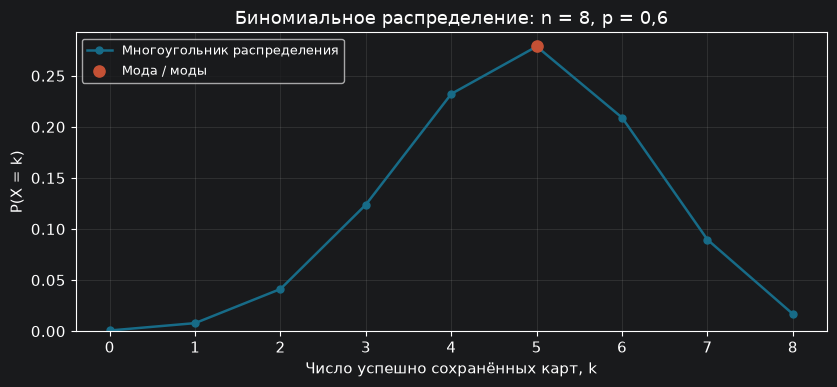

In [13]:
polygon(x_bin, prob_bin, 'Биномиальное распределение: n = 8, p = 0,6',
        'Число успешно сохранённых карт, k', modes_bin, '#176B87')

### 2. Распределение Пуассона

> Автоматическая камера наблюдает метеоры в фиксированной области неба. В рамках модели метеоры появляются как однородный пуассоновский поток с интенсивностью 2 события в час: число событий в непересекающихся интервалах независимо. Случайная величина $Y$ — число зарегистрированных метеоров за 2 часа непрерывного наблюдения. Составить закон распределения, найти все характеристики и построить многоугольник распределения.

#### Закон распределения

$$P(Y=k)=e^{-4}\frac{4^k}{k!},\qquad k=0,1,2,\ldots.$$

При $k<0$ вероятность равна нулю

In [14]:
rate, hours = 2, 2
lam = rate * hours
rv_pois = poisson(lam)
limit_pois = int(rv_pois.ppf(0.9999))
x_pois = np.arange(0, limit_pois + 1)
prob_pois = rv_pois.pmf(x_pois)
tail_pois = float(rv_pois.sf(limit_pois))
display(distribution_table(x_pois, prob_pois))
print(f'Сумма показанных вероятностей: {prob_pois.sum():.9f}')
print(f'P(Y > {limit_pois}) = {tail_pois:.9f}')

,k,P(X = k)
0,0,0.018316
1,1,0.073263
2,2,0.146525
3,3,0.195367
4,4,0.195367
5,5,0.156293
6,6,0.104196
7,7,0.059540
8,8,0.029770
9,9,0.013231


Сумма показанных вероятностей: 0.999923672
P(Y > 13) = 0.000076328


### Числовые характеристики

$$M(Y)=\lambda=4,\qquad D(Y)=\lambda=4,\qquad\sigma(Y)=\sqrt{4}=2.$$

Так как $\lambda=4$ — целое положительное число, у распределение две моды: 3 и 4

In [15]:
modes_pois = modes_from_pmf(x_pois, prob_pois)
characteristics(rv_pois, modes_pois)

,Характеристика,Значение
0,M(X),4.000000
1,D(X),4.000000
2,σ(X),2.000000
3,Мода,"[3, 4]"


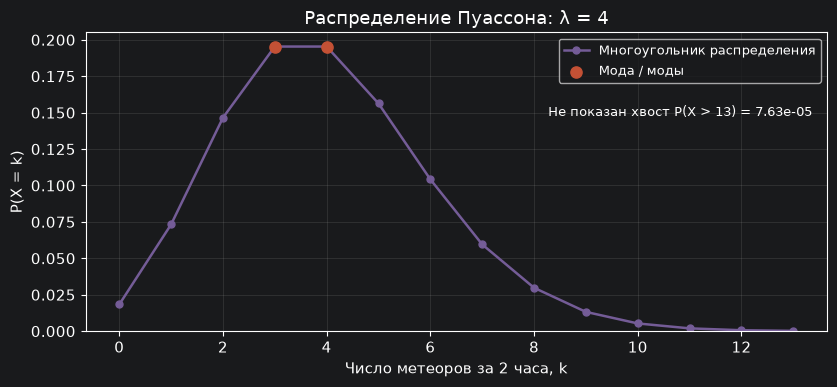

In [16]:
polygon(x_pois, prob_pois, 'Распределение Пуассона: λ = 4',
        'Число метеоров за 2 часа, k', modes_pois, '#745C97', tail_pois)

## 3. Геометрическое распределение

> Генератор создаёт случайные головоломки. Каждая попытка независимо от предыдущих даёт головоломку с единственным решением с вероятностью 0,25. Генерация продолжается до первой такой головоломки. Случайная величина $Z$ — число попыток, включая успешную. Составить закон распределения, найти характеристики и построить многоугольник распределения.

### Закон распределения

$$P(Z=k)=0{,}25\,(0{,}75)^{k-1},\qquad k=1,2,3,\ldots.$$

Для остальных целых $k$ вероятность равна нулю

In [17]:
p_geom = 0.25
rv_geom = geom(p_geom)
x_geom_table = np.arange(1, 13)
display(distribution_table(x_geom_table, rv_geom.pmf(x_geom_table)))
print(f'P(Z > 12) = {rv_geom.sf(12):.9f}')
print(f'Сумма первых 12 вероятностей и хвоста: {rv_geom.pmf(x_geom_table).sum() + rv_geom.sf(12):.12f}')

limit_geom = int(rv_geom.ppf(0.999))
x_geom = np.arange(1, limit_geom + 1)
prob_geom = rv_geom.pmf(x_geom)
tail_geom = float(rv_geom.sf(limit_geom))
print(f'Для графика: k от 1 до {limit_geom}; P(Z > {limit_geom}) = {tail_geom:.9f}')

,k,P(X = k)
0,1,0.250000
1,2,0.187500
2,3,0.140625
3,4,0.105469
4,5,0.079102
5,6,0.059326
6,7,0.044495
7,8,0.033371
8,9,0.025028
9,10,0.018771


P(Z > 12) = 0.031676352
Сумма первых 12 вероятностей и хвоста: 1.000000000000
Для графика: k от 1 до 25; P(Z > 25) = 0.000752543


### Числовые характеристики

$$M(Z)=\frac1p=4,\qquad D(Z)=\frac{1-p}{p^2}=\frac{0{,}75}{0{,}25^2}=12,$$
$$\sigma(Z)=\sqrt{12}\approx3{,}464102.$$

Последовательность вероятностей убывает: $p_{k+1}/p_k=0{,}75<1$, поэтому мода $m_0=1$

In [18]:
modes_geom = modes_from_pmf(x_geom, prob_geom)
characteristics(rv_geom, modes_geom)

,Характеристика,Значение
0,M(X),4.000000
1,D(X),12.000000
2,σ(X),3.464102
3,Мода,[1]


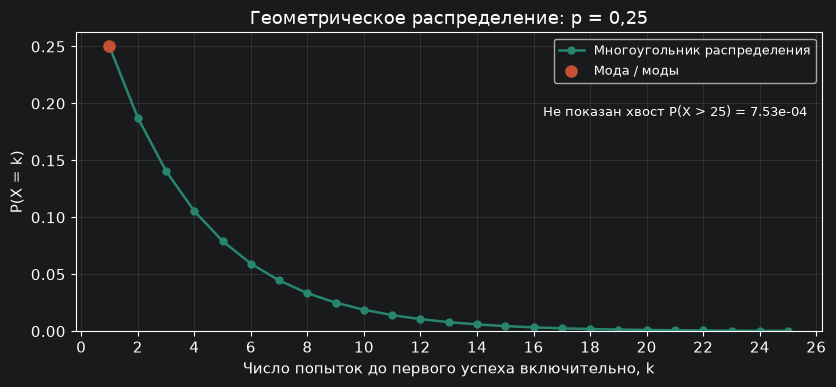

In [19]:
polygon(x_geom, prob_geom, 'Геометрическое распределение: p = 0,25',
        'Число попыток до первого успеха включительно, k', modes_geom, '#27866C', tail_geom)

### 4. Гипергеометрическое распределение

> В цифровом архиве 12 материалов: 4 старинные карты и 8 фотографий. Для выставки случайно выбирают 5 различных материалов без возвращения; все наборы из 5 материалов равновероятны. Случайная величина $W$ — число карт среди выбранных материалов. Составить закон распределения, найти характеристики и построить многоугольник распределения.

#### Закон распределения

Общий диапазон: $\max(0,n-(N-K))\leq k\leq\min(n,K)$. Здесь он равен $0\leq k\leq4$.

$$P(W=k)=\frac{\binom{4}{k}\binom{8}{5-k}}{\binom{12}{5}},\qquad k=0,1,2,3,4.$$

Для остальных целых $k$ вероятность равна нулю

In [20]:
total, maps, sample_size = 12, 4, 5
rv_hyper = hypergeom(M=total, n=maps, N=sample_size)
lower = max(0, sample_size - (total - maps))
upper = min(sample_size, maps)
x_hyper = np.arange(lower, upper + 1)
prob_hyper = rv_hyper.pmf(x_hyper)
display(distribution_table(x_hyper, prob_hyper))
print(f'Сумма вероятностей: {prob_hyper.sum():.12f}')

,k,P(X = k)
0,0,0.070707
1,1,0.353535
2,2,0.424242
3,3,0.141414
4,4,0.010101


Сумма вероятностей: 1.000000000000


### Числовые характеристики

$$M(W)=n\frac KN=5\cdot\frac4{12}=\frac53\approx1{,}666667,$$
$$D(W)=n\frac KN\left(1-\frac KN\right)\frac{N-n}{N-1}
=5\cdot\frac13\cdot\frac23\cdot\frac7{11}=\frac{70}{99}\approx0{,}707071,$$
$$\sigma(W)=\sqrt{\frac{70}{99}}\approx0{,}840875.$$

По таблице наибольшая вероятность — $P(W=2)=336/792$. Поэтому мода $m_0=2$

In [21]:
modes_hyper = modes_from_pmf(x_hyper, prob_hyper)
characteristics(rv_hyper, modes_hyper)

,Характеристика,Значение
0,M(X),1.666667
1,D(X),0.707071
2,σ(X),0.840875
3,Мода,[2]


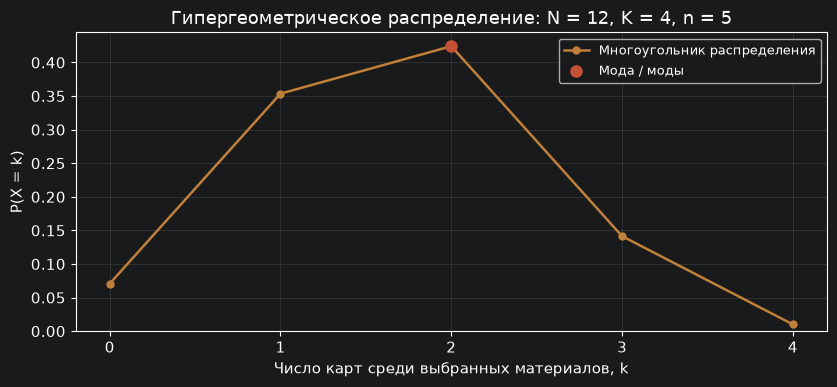

In [22]:
polygon(x_hyper, prob_hyper, 'Гипергеометрическое распределение: N = 12, K = 4, n = 5',
        'Число карт среди выбранных материалов, k', modes_hyper, '#C08038')